# 06 · District scores, certainty and the default plan

For each district we combine four factors, each rescaled 0–1 across the 30 districts:

| Factor | Measure | Default weight |
|---|---|---|
| **Water gain** | Extra RWF per irrigated hectare per season = Σ crop share × rain-fed yield × water bonus × price | 40% |
| **Adoption gap** | 1 − share of small-farm area already irrigated | 20% |
| **Dryness** | Less June–August rain scores higher | 20% |
| **Poverty** | EICV7 poverty rate | 20% |

Crop shares, rain-fed sole-crop yields, irrigated share and farm-gate prices come from SAS 2023–2025 (the most
recent three years). This notebook writes the two files the API serves: `data/processed/crops.json` and
`districts.json`, plus `season_c.json` from notebook 05. They hold aggregates only.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from kuhira import build, plan, style
from kuhira import district_stats as ds
from kuhira import season_c as sc
from kuhira.paths import INTERIM
from kuhira.rainfall import dry_season_mm

style.use()
plots = pd.read_parquet(INTERIM / "plots.parquet")
recent = ds.recent_small(plots)
bonus = pd.read_csv(INTERIM / "water_bonus.csv")
crops = build.crops_table(bonus, ds.crop_prices(recent), ds.national_rainfed_yields(recent))
districts = build.districts_table(recent, dry_season_mm(pd.read_parquet(INTERIM / "rain_monthly.parquet")),
                                  build.load_poverty())
dry = pd.read_parquet(INTERIM / "plots_C.parquet")
season_c = build.season_c_summary(sc.plot_values(dry, ds.crop_prices(recent)), sc.uptake_by_year(plots, dry),
                                  sc.irrigated_crop_mix(dry))
build.write(crops, districts, season_c)
pd.DataFrame(crops)[["crop", "bonus_pct", "p_value", "price_rwf_per_kg", "yield_kg_per_ha"]]

,crop,bonus_pct,p_value,price_rwf_per_kg,yield_kg_per_ha
0,Maize,14.6,0.0000,340.0,1424.010017
1,Beans,-10.3,0.0009,650.0,644.916631
2,Irish potato,9.7,0.0994,350.0,7753.945231
3,Sweet potato,15.2,0.0000,200.0,7353.017202
4,Vegetables,20.3,0.0000,250.0,6702.852584
5,Sorghum,-4.0,0.6112,500.0,1122.050525
6,Cassava,-3.5,0.5842,250.0,8410.742922
7,Paddy rice,9.0,0.0655,500.0,2513.639646
8,Soybean,-1.0,0.8939,700.0,304.390570
9,Wheat,NaN,NaN,700.0,1228.226566


## Ranking with the default weights

In [2]:
plan.load_crops.cache_clear(); plan.load_districts.cache_clear(); plan.load_season_c.cache_clear()
C, D = plan.load_crops(), plan.load_districts()
ranked = pd.DataFrame(plan.score(D, C, plan.Weights()))
ranked[["rank", "district", "province", "score", "gain_rwf_per_ha", "irrigated_share", "dry_season_mm",
        "poverty_rate_pct"]].head(10)

,rank,district,province,score,gain_rwf_per_ha,irrigated_share,dry_season_mm,poverty_rate_pct
0,1,Nyamagabe,South,84.8,49014,0.0121,75.7,51.39
1,2,Nyaruguru,South,78.9,50185,0.0216,66.1,39.70
2,3,Rubavu,West,73.3,47974,0.0019,119.0,38.81
3,4,Gakenke,North,63.9,40392,0.0110,78.4,24.47
4,5,Karongi,West,62.4,36996,0.0149,91.8,38.19
5,6,Nyagatare,East,61.3,31820,0.0183,60.8,36.37
6,7,Ngororero,West,59.2,34012,0.0096,85.9,30.24
7,8,Burera,North,57.8,35708,0.0037,94.0,21.79
8,9,Rutsiro,West,56.1,28555,0.0034,109.5,40.78
9,10,Nyamasheke,West,55.7,29434,0.0149,96.9,42.67


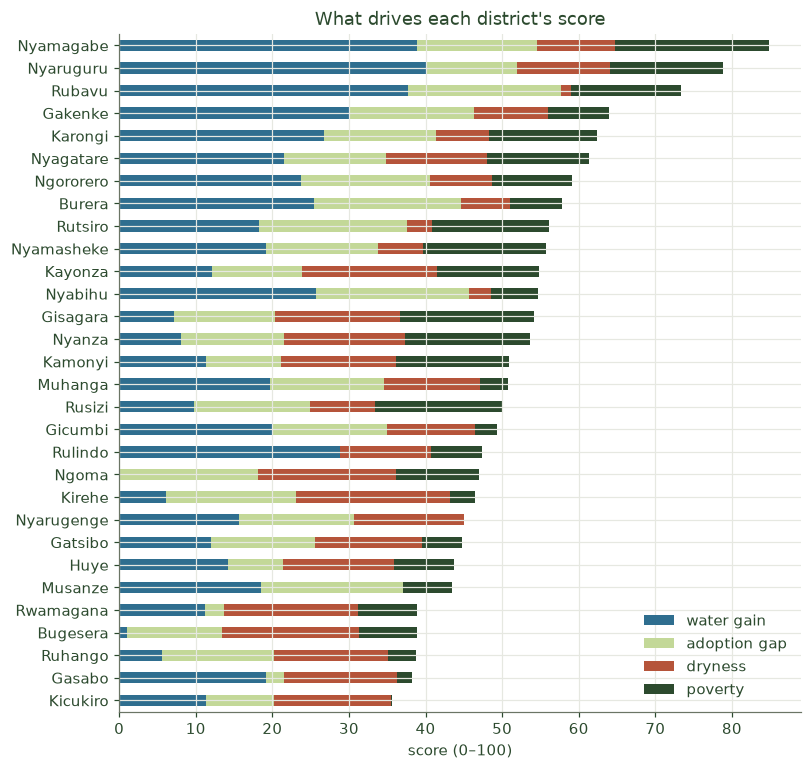

In [3]:
f = pd.DataFrame(ranked.factors.tolist(), index=ranked.district)
ax = (f * pd.Series(plan.Weights().model_dump()) * 100).plot(
    kind="barh", stacked=True, figsize=(8, 8), color=[style.WATER, style.PRIMARY, style.CLAY, style.FOREST])
ax.invert_yaxis()
ax.set(xlabel="score (0–100)", ylabel="", title="What drives each district's score")
ax.legend(["water gain", "adoption gap", "dryness", "poverty"], frameon=False, loc="lower right");

## What the bean penalty costs each district
Across districts, beans' share of the crop area barely predicts the water gain (other crops matter more). The
direct test: recompute each district's gain as if irrigated beans broke even, and compare.

In [4]:
no_penalty = C | {"Beans": C["Beans"].model_copy(update={"bonus_pct": 0.0})}
beans = pd.DataFrame([{
    "district": d.district,
    "bean_share": next((c.share for c in d.crops if c.crop == "Beans"), 0),
    "gain_rwf_per_ha": plan.gain_per_ha(d, C),
    "gain_if_beans_broke_even": plan.gain_per_ha(d, no_penalty),
} for d in D.values()])
beans["penalty_pct"] = 100 * (1 - beans.gain_rwf_per_ha / beans.gain_if_beans_broke_even)
beans.sort_values("penalty_pct", ascending=False).head(8).round(2)

,district,bean_share,gain_rwf_per_ha,gain_if_beans_broke_even,penalty_pct
15,Ngoma,0.23,10368.57,20646.15,49.78
14,Musanze,0.30,28810.94,49198.34,41.44
12,Kirehe,0.27,16456.65,25842.97,36.32
0,Bugesera,0.23,11426.30,17833.82,35.93
1,Burera,0.28,35708.41,55199.38,35.31
27,Rusizi,0.25,20060.55,30237.75,33.66
5,Gicumbi,0.28,30315.69,45465.50,33.32
6,Gisagara,0.27,17543.37,25568.69,31.39


Counting the bean penalty **halves Ngoma's water gain** and cuts Musanze's by about 40%. A planner using a
blanket "irrigation raises yields" assumption would overrate these districts; Kuhira does not.

## Is the ranking fragile?
Re-rank under four very different weightings. Districts that stay near the top whatever you believe are the
safe first picks.

In [5]:
schemes = {"default": plan.Weights(), "gain only": plan.Weights(gain=1, gap=0, dryness=0, poverty=0),
           "equal": plan.Weights(gain=.25, gap=.25, dryness=.25, poverty=.25),
           "pro-poor": plan.Weights(gain=.2, gap=.2, dryness=.2, poverty=.4),
           "drought": plan.Weights(gain=.3, gap=.1, dryness=.5, poverty=.1)}
ranks = pd.DataFrame({k: {r["district"]: r["rank"] for r in plan.score(D, C, w)} for k, w in schemes.items()})
ranks.assign(worst=ranks.max(axis=1)).sort_values("default").head(10)

,default,gain only,equal,pro-poor,drought,worst
Nyamagabe,1,2,1,1,2,2
Nyaruguru,2,1,2,2,1,2
Rubavu,3,3,3,3,24,24
Gakenke,4,4,8,15,9,15
Karongi,5,6,7,7,20,20
Nyagatare,6,10,4,6,5,10
Ngororero,7,9,10,14,21,21
Burera,8,8,16,16,25,25
Rutsiro,9,16,12,9,29,29
Nyamasheke,10,14,13,8,27,27


## How sure is each rank?
The water bonuses are estimates with error bars (notebook 03). Re-rank 300 times, each time drawing every counted
bonus from its uncertainty; record where each district lands. The bar is the range covering 90% of runs, the dot the
rank shown in the app. Crops the ranking counts as zero stay at zero, so the ranges describe the ranking as built.

,rank,district,rank_low,rank_high,top_share
0,1,Nyamagabe,1,2,1.00
1,2,Nyaruguru,2,4,1.00
2,3,Rubavu,1,7,0.99
3,4,Gakenke,3,7,0.99
4,5,Karongi,4,8,0.99
5,6,Nyagatare,2,18,0.76
6,7,Ngororero,6,14,0.88
7,8,Burera,6,17,0.72
8,9,Rutsiro,7,15,0.66
9,10,Nyamasheke,8,13,0.62


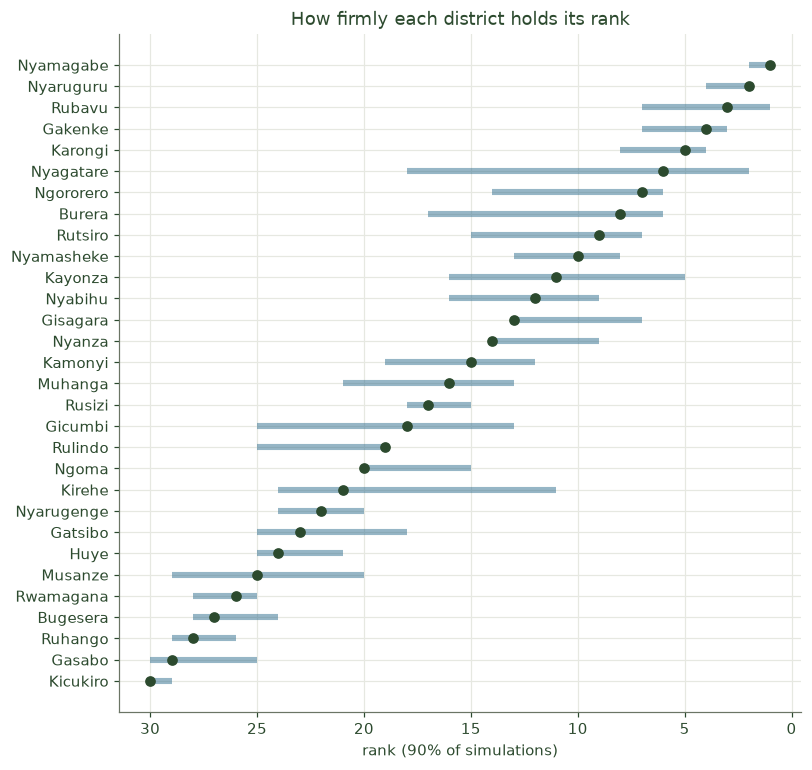

In [6]:
u = plan.rank_uncertainty(D, C, plan.Weights())
cert = ranked[["rank", "district"]].assign(**{k: ranked.district.map(lambda d, k=k: u[d][k]) for k in ["rank_low", "rank_high", "top_share"]})
fig, ax = plt.subplots(figsize=(8, 8))
ax.hlines(cert.district, cert.rank_low, cert.rank_high, color=style.WATER, lw=4, alpha=0.5)
ax.scatter(cert["rank"], cert.district, color=style.FOREST, zorder=3)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set(xlabel="rank (90% of simulations)", title="How firmly each district holds its rank")
cert.head(10)

The top two hold firm: Nyamagabe ranks 1–2 and Nyaruguru 2–4 in 90% of runs. The top five all stay in the top ten
in 99% of runs. Mid-table places move several ranks, so read ranks 6–20 as a band, not an order. Nyagatare is the
widest (2–18): its gain rests on maize, whose bonus is uncertain.

**Robustness: what if the uncertain crops counted too?** Irish potato (+10%) and rice (+9%) lean positive but are
not clearly different from zero, so the ranking counts them as zero. Drawing them as well:

In [7]:
g = plan.rank_uncertainty(D, C, plan.Weights(), include_uncertain=True)
cert.assign(if_uncertain_counted=cert.district.map(lambda d: f"{g[d]['rank_low']}–{g[d]['rank_high']}")).head(10)

,rank,district,rank_low,rank_high,top_share,if_uncertain_counted
0,1,Nyamagabe,1,2,1.00,1–3
1,2,Nyaruguru,2,4,1.00,3–7
2,3,Rubavu,1,7,0.99,1–3
3,4,Gakenke,3,7,0.99,6–19
4,5,Karongi,4,8,0.99,8–16
5,6,Nyagatare,2,18,0.76,4–19
6,7,Ngororero,6,14,0.88,7–18
7,8,Burera,6,17,0.72,4–14
8,9,Rutsiro,7,15,0.66,5–13
9,10,Nyamasheke,8,13,0.62,9–22


Nyamagabe and Rubavu stay at the top either way. Gakenke and Karongi drop furthest (to about 6–19 and 8–16), so
their places depend on the choice to count only clear effects. This is why the app shows each rank's range and the
Method page names the choice.

## The default plan: the remaining 13,368 ha
PSTA5 targets 41,031 ha of small-scale irrigation by 2028/29; 27,663 ha were in place by FY2024/25. Hectares are
split in proportion to score × small-farm cropland. Kit cost: ~RWF 1.35 M/ha (RAB 2019, $1,500/ha), 50% subsidy.

In [8]:
S = plan.load_season_c()
alloc = plan.allocate(plan.score(D, C, plan.Weights()), plan.REMAINING_HA, plan.COST_PER_HA_RWF, plan.SUBSIDY_REGULAR,
                      S.value_rwf_per_ha, S.uptake)
pd.DataFrame(alloc["districts"]).head(10)

,district,rank,score,hectares,public_cost_rwf,farmer_cost_rwf,extra_value_rwf_per_year,season_c_value_rwf_per_year
0,Nyamagabe,1,84.8,683,461134790,461134790,66969068,460435806
1,Nyaruguru,2,78.9,480,323811922,323811922,48149633,323321090
2,Rubavu,3,73.3,369,249321283,249321283,35439820,248943364
3,Gakenke,4,63.9,598,403733740,403733740,48318854,403121764
4,Karongi,5,62.4,497,335515370,335515370,36778449,335006798
5,Nyagatare,6,61.3,1112,750413676,750413676,70750113,749276204
6,Ngororero,7,59.2,492,332137165,332137165,33471553,331633714
7,Burera,8,57.8,461,310962128,310962128,32900254,310490774
8,Rutsiro,9,56.1,339,229087838,229087838,19382528,228740589
9,Nyamasheke,10,55.7,407,274823226,274823226,23967842,274406651


In [9]:
t = alloc["totals"]
pd.Series({"hectares": f"{t['hectares']:,}", "public cost (RWF bn)": round(t["public_cost_rwf"] / 1e9, 1),
           "farmers' share (RWF bn)": round(t["farmer_cost_rwf"] / 1e9, 1),
           "yield gain A+B per year (RWF bn)": round(t["extra_value_rwf_per_year"] / 1e9, 1),
           "dry-season harvest per year (RWF bn)": round(t["season_c_value_rwf_per_year"] / 1e9, 1)})

hectares                                13,368
public cost (RWF bn)                       9.0
farmers' share (RWF bn)                    9.0
yield gain A+B per year (RWF bn)           0.8
dry-season harvest per year (RWF bn)       9.0
dtype: object

**Reading the totals honestly.** The yield gain in Seasons A and B alone is small: about RWF 0.8 bn a year against
RWF 18 bn of kit. The dry season changes the picture. With about 43% of new kit land carrying a Season C crop
(notebook 05), the extra dry-season harvest is about **RWF 9.0 bn a year**. That is harvest value before seed,
fertilizer and labour, so it overstates profit, but it shows where irrigation's value lies. Neither figure changes
the ranking, which depends only on how districts compare.